In [25]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pathlib import Path

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
# Load all datasets from the results directory
# Pattern: "scoring/{anonymization_method}/{embedding_method}/{aggregation_method}/scores.parquet"
SCORES_PATH = Path("../../results/scoring")

_scores = []
for anonymization_method in SCORES_PATH.iterdir():
    if not anonymization_method.is_dir():
        continue
    for embedding_method in anonymization_method.iterdir():
        if not embedding_method.is_dir():
            continue
        for aggregation_method in embedding_method.iterdir():
            if not aggregation_method.is_dir():
                continue
            _score = pd.read_parquet(str(aggregation_method / "scores.parquet"))
            for _, _s in _score.iterrows():
                _scores.append(
                    {
                        "key": f"{anonymization_method.name}/{embedding_method.name}/{aggregation_method.name}",
                        "anonymization_method": anonymization_method.name,
                        "embedding_method": embedding_method.name,
                        "aggregation_method": aggregation_method.name,
                        "accuracy": _s["accuracy"],
                    }
                )
scores = pd.DataFrame(_scores)
scores

,key,anonymization_method,embedding_method,aggregation_method,accuracy
0,gaussianblur/ghostfacenet/pooling_mean,gaussianblur,ghostfacenet,pooling_mean,0.171278
1,gaussianblur/ghostfacenet/pooling_mean,gaussianblur,ghostfacenet,pooling_mean,0.199324
2,gaussianblur/ghostfacenet/pooling_mean,gaussianblur,ghostfacenet,pooling_mean,0.186691
3,gaussianblur/ghostfacenet/pooling_max,gaussianblur,ghostfacenet,pooling_max,0.146245
4,gaussianblur/ghostfacenet/pooling_max,gaussianblur,ghostfacenet,pooling_max,0.160473
...,...,...,...,...,...
475,none/facenet512/none,none,facenet512,none,0.583467
476,none/facenet512/none,none,facenet512,none,0.572381
477,none/facenet512/pooling_median,none,facenet512,pooling_median,0.666667
478,none/facenet512/pooling_median,none,facenet512,pooling_median,0.701014


AttributeError: Rectangle.set() got an unexpected keyword argument 'col'

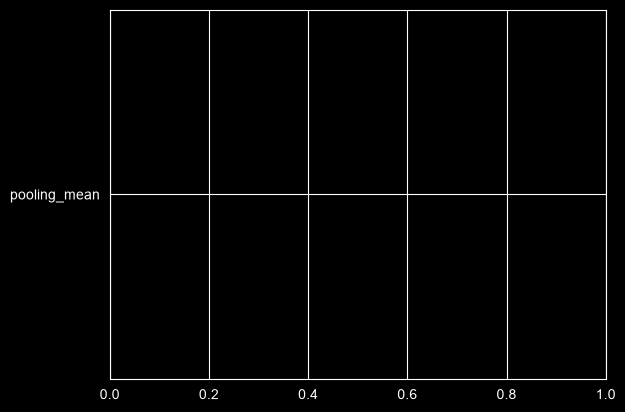

In [57]:
# Visualize the mean accuracy (with error bars) for each combination of aggregation and anonymization method.

filtered_scores = scores#[(scores["embedding_method"] == "vggface")]
sns.barplot(
    data=filtered_scores,
    y="aggregation_method",
    x="accuracy",
    orient="h",
    hue="anonymization_method",
    palette=sns.color_palette("BuGn_r", n_colors=len(filtered_scores["anonymization_method"].unique())),
    ec="k",
)

plt.xlabel("Mean Accuracy")
plt.ylabel("Aggregation")
legend = plt.legend(title='Anonymization', loc='upper right')
plt.show()